# 05 - User Segment Analysis (Casual vs Registered)

**Objective:** compare how casual and registered users contribute to demand across time and conditions.
**Grain:** shares and daily patterns come from `day.csv`; intraday patterns from `hour.csv`. Counts are **rentals, not unique users**.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore", message="findfont")
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.visualization.style import apply_matplotlib_style
apply_matplotlib_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 40)
from src.data.clean import load_processed
from src.analysis import kpis as K, stats as S
from src.visualization import figures as F
day, hour = load_processed("day"), load_processed("hour")

## Overall contribution

In [2]:
k = K.kpi_frame(K.headline_kpis(day)).set_index("name")
k.loc[["Registered rentals", "Casual rentals", "Registered share", "Casual share", "Casual-to-registered ratio"]]

,value,unit,grain,note
name,,,,
Registered rentals,"2,672,662.00",rentals,period total,
Casual rentals,"620,017.00",rentals,period total,
Registered share,0.81,share,ratio,
Casual share,0.19,share,ratio,
Casual-to-registered ratio,0.23,ratio,ratio,


## By day type and weekday

,days,mean_casual,mean_registered,casual_share
day_type,,,,
Working day,500,606.57,"3,978.25",0.13
Weekend,210,"1,401.78","2,987.91",0.32
Holiday,21,"1,064.71","2,670.29",0.29


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


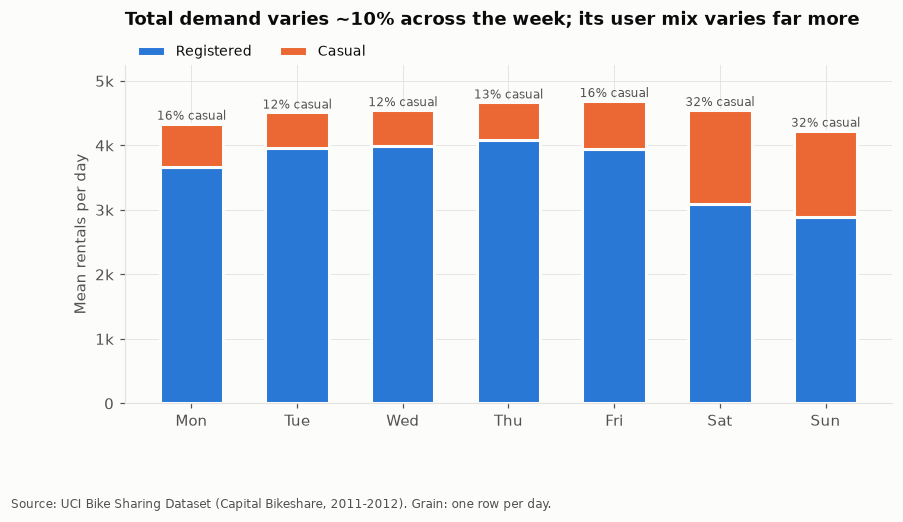

In [3]:
display(K.daily_summary_by(day, 'day_type')[['days', 'mean_casual', 'mean_registered', 'casual_share']])
F.fig_weekday_segments(day); plt.show()

## Intraday shapes

,day_type,shape_correlation,casual_commute_share,registered_commute_share,casual_peak_hour,registered_peak_hour
0,Working day,0.66,0.34,0.54,17,17
1,Weekend,0.97,0.24,0.27,14,12
2,Holiday,0.89,0.24,0.35,13,17


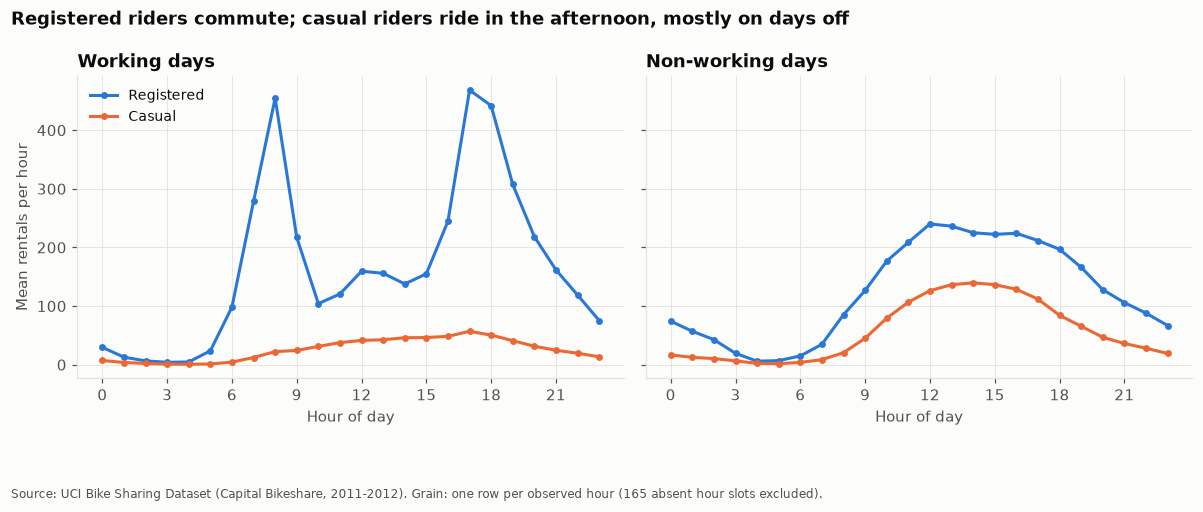

In [4]:
display(S.hourly_profile_similarity(hour))
F.fig_segment_hourly(hour); plt.show()

- On working days, about 54% of registered rentals fall in the commute windows (7-9h, 17-19h), compared with about 34% of casual rentals. The shapes correlate only moderately (r = 0.66).
- On weekends the two shapes are almost identical (r = 0.97): everyone rides around midday.

## Seasonality of the mix

,mean_casual,mean_registered,casual_share
season_label,,,
Winter,334.93,"2,269.20",0.13
Spring,"1,106.10","3,886.23",0.22
Summer,"1,202.61","4,441.69",0.21
Fall,729.11,"3,999.05",0.15


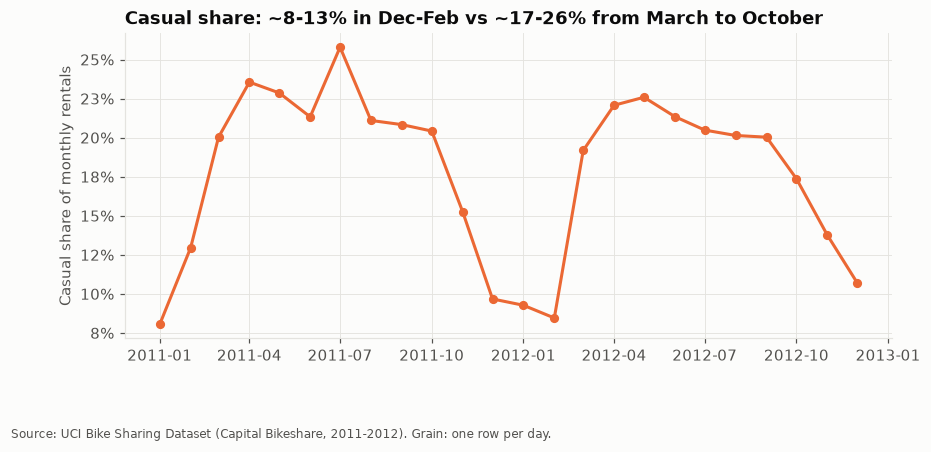

In [5]:
display(K.daily_summary_by(day, 'season_label')[['mean_casual', 'mean_registered', 'casual_share']])
F.fig_casual_share_month(day); plt.show()

## Weather sensitivity by segment

In [6]:
K.weather_sensitivity(day)[['casual_index', 'registered_index', 'days']]

,casual_index,registered_index,days
weather_group,,,
Clear / partly cloudy,100.00,100.00,463
Mist / cloudy,71.30,85.58,247
Rain / snow,19.24,41.35,21


## Conclusions
1. Registered users account for 81% of rentals and drive the working-day commute peaks.
2. Casual users are a leisure segment: 32% of weekend rentals versus 13% on working days, concentrated in March-October afternoons.
3. Casual demand is far more sensitive to bad weather and to the season.

**Limitations:** no user identifiers, so we cannot tell how many people these rentals represent or whether casual users later register.